# Probability laws: what changes when the assumptions change?

We will compare tails, condition on information, and transform distributions using Convexity's law interface. The useful question is not whether a method returns an array: it is what probability model that array represents.

The inputs are specified laws and finite scenarios. There is no fitting in this notebook. Every random sample uses an explicit generator, and every exact quantity below is evaluated by a Convexity distribution. Start with the equal-variance comparison, then follow the same objects into mixtures and conditional laws. [API and shape conventions](../docs/distributions.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import distributions as dist

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.grid": True,
                     "grid.alpha": .18, "figure.dpi": 110})

## Equal variance does not mean equal tail risk

`normal(scale=...)` uses standard deviation. `student_t(scale=...)` uses a scale parameter whose variance is $s^2\nu/(\nu-2)$ when $\nu>2$. We choose the t scale so both laws have variance one.

Inspect both the centre and the log-scale survival curve. The t distribution can place more mass very near zero **and** far from zero, with less mass in between. The table asks the same questions of both objects: a tail probability and a high quantile.

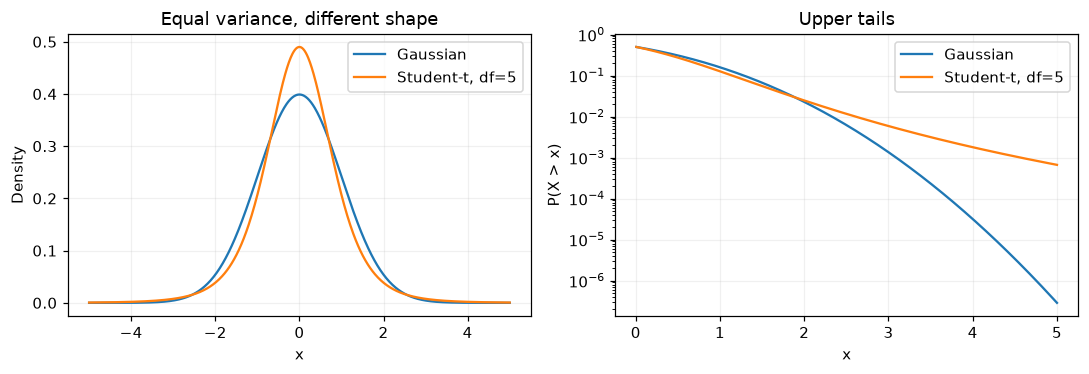

In [2]:
gaussian = dist.normal()
student = dist.student_t(5, scale=np.sqrt(3 / 5))
x = np.linspace(-5, 5, 700)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for law, label in [(gaussian, 'Gaussian'), (student, 'Student-t, df=5')]:
    axes[0].plot(x, law.density(x), label=label)
    positive = x[x >= 0]
    axes[1].semilogy(positive, law.survival(positive), label=label)
axes[0].set(xlabel='x', ylabel='Density', title='Equal variance, different shape')
axes[1].set(xlabel='x', ylabel='P(X > x)', title='Upper tails')
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

In [3]:
pd.DataFrame({name: {"mean": float(law.mean()), "variance": float(law.variance()),
    "P(X > 3)": float(law.survival(3)), "99% quantile": float(law.quantile(.99))}
    for name, law in {"Gaussian": gaussian, "Student-t (df=5)": student}.items()}).T

,mean,variance,P(X > 3),99% quantile
Gaussian,0.0,1.0,0.001350,2.326348
Student-t (df=5),0.0,1.0,0.005862,2.606464


## A density can mean probability mass

A Poisson count and a binomial count can have the same mean while having different variance and support. `density(k)` returns a mass here, not a continuous density. The binomial distribution cannot exceed its number of trials; the Poisson distribution has no finite upper endpoint.

CDF means $P(X\leq k)$ and survival means $P(X>k)$. Quantiles are supported integer outcomes, so several probability levels may give the same answer.

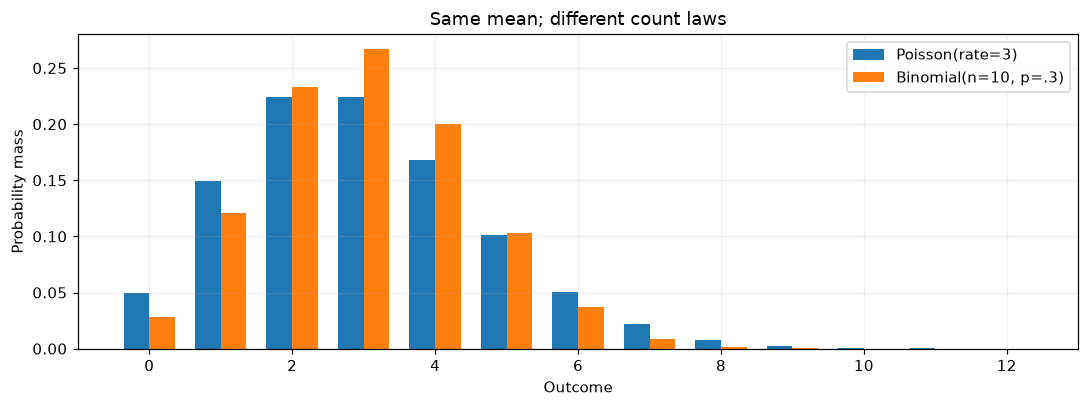

In [4]:
counts = dist.poisson(3)
successes = dist.binomial(10, 0.3)
k = np.arange(13)
fig, ax = plt.subplots()
ax.bar(k - 0.18, counts.density(k), width=0.36, label='Poisson(rate=3)')
ax.bar(k + 0.18, successes.density(k), width=0.36, label='Binomial(n=10, p=.3)')
ax.set(xlabel='Outcome', ylabel='Probability mass', title='Same mean; different count laws')
ax.legend()
plt.tight_layout()
plt.show()

In [5]:
pd.DataFrame({"probability": [.1, .5, .9, .99],
              "Poisson quantile": counts.quantile([.1, .5, .9, .99]),
              "Binomial quantile": successes.quantile([.1, .5, .9, .99])})

,probability,Poisson quantile,Binomial quantile
0,0.10,1.0,1.0
1,0.50,3.0,3.0
2,0.90,5.0,5.0
3,0.99,8.0,7.0


## A finite scenario law preserves the joint outcomes

An empirical law gives mass only to the supplied scenarios. Repeated atoms combine; zero-weight rows disappear. Quantiles use the inverse empirical CDF, without interpolation.

The two-coordinate example below makes conditioning tangible: after learning the first coordinate, only compatible rows remain, with their masses renormalized. Mapping a whole row to its sum preserves its dependence. Adding separately sampled marginals would describe a different experiment.

In [6]:
atoms = dist.empirical([0, 10, 10, 999], weights=[1, 1, 2, 0])
joint_atoms = dist.empirical([[0, 1], [0, 3], [1, 4]], [1, 3, 4])
conditional_atoms = joint_atoms.condition([0], [0])

In [7]:
support = np.array([0., 10., 999.])
display(pd.DataFrame({"outcome": support, "probability mass": atoms.density(support)}))
pd.DataFrame({"quantity": ["unconditional sum", "second coordinate given first = 0"],
              "mean": [float(joint_atoms.map(lambda row: row.sum()).mean()),
                       float(conditional_atoms.mean()[0])]})

,outcome,probability mass
0,0.0,0.25
1,10.0,0.75
2,999.0,0.00


,quantity,mean
0,unconditional sum,3.75
1,second coordinate given first = 0,2.50


## Mixtures: uncertainty within and between components

The mixture first selects a component, then draws from it. Its variance includes both each component's spread and separation between component means. A Gaussian with matching first two moments will usually have a different density and different quantiles.

Use the density plot to distinguish the components, and the CDF to read quantiles. The histogram is a finite sample from the mixture, so it should be close to the density without matching every bin.

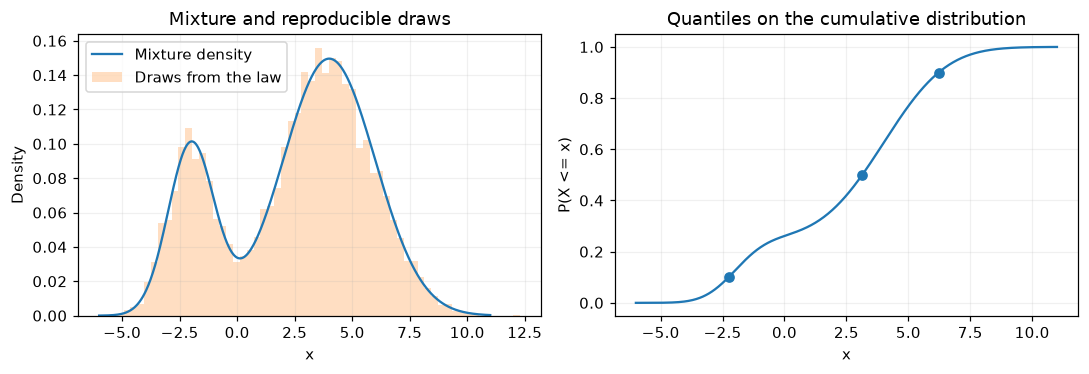

In [8]:
mixed = dist.mixture([dist.normal(-2, 1), dist.normal(4, 2)], weights=[1, 3])
p = np.array([0.1, 0.5, 0.9])
q = mixed.quantile(p)
x = np.linspace(-6, 11, 700)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(x, mixed.density(x), label='Mixture density')
axes[0].hist(mixed.sample(8000, rng=rng), bins=60, density=True, alpha=0.25, label='Draws from the law')
axes[0].set(xlabel='x', ylabel='Density', title='Mixture and reproducible draws')
axes[0].legend()
axes[1].plot(x, mixed.cdf(x))
axes[1].scatter(q, p)
axes[1].set(xlabel='x', ylabel='P(X <= x)', title='Quantiles on the cumulative distribution')
plt.tight_layout()
plt.show()

In [9]:
matched = dist.normal(float(mixed.mean()), np.sqrt(float(mixed.variance())))
pd.DataFrame({"probability": [.01, .1, .5, .9, .99],
              "mixture": mixed.quantile([.01, .1, .5, .9, .99]),
              "moment-matched Gaussian": matched.quantile([.01, .1, .5, .9, .99])})

,probability,mixture,moment-matched Gaussian
0,0.01,-3.752535,-4.856558
1,0.10,-2.260138,-1.552622
2,0.50,3.138546,2.500000
3,0.90,6.221543,6.552622
4,0.99,8.432726,9.856558


## Conditioning changes more than the mean

`condition([1], [value])` conditions on coordinate 1 and returns a law for the remaining coordinates, still with vector event shape `(1,)`. The Gaussian conditional variance is constant as the observed value changes. In a multivariate t law, an extreme observation also changes the inferred common scale, widening the conditional law.

The next comparison makes the **unconditional covariances equal**. This matters: the same Gaussian covariance and t *shape* do not imply the same covariance. Compare the conditional variance curves rather than attributing an initial scale mismatch to conditioning.

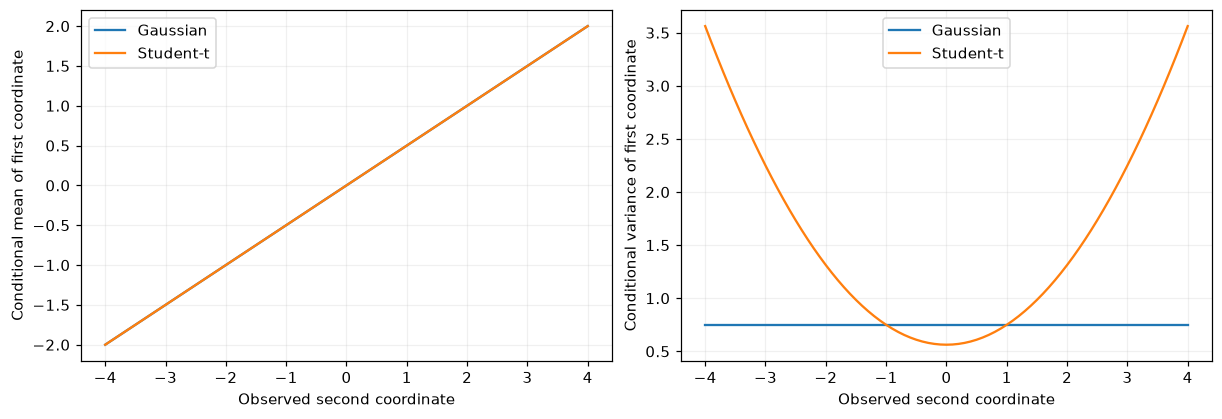

In [10]:
correlation = np.array([[1., .5], [.5, 1.]])
joint_gaussian = dist.multivariate_normal([0., 0.], correlation)
joint_student = dist.multivariate_student_t(5, [0., 0.], correlation * 3/5)
observed_values = np.linspace(-4, 4, 81)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
for label, law in {"Gaussian": joint_gaussian, "Student-t": joint_student}.items():
    conditionals = [law.condition([1], [value]) for value in observed_values]
    axes[0].plot(observed_values, [c.mean()[0] for c in conditionals], label=label)
    axes[1].plot(observed_values, [c.covariance()[0, 0] for c in conditionals], label=label)
axes[0].set(xlabel="Observed second coordinate", ylabel="Conditional mean of first coordinate")
axes[1].set(xlabel="Observed second coordinate", ylabel="Conditional variance of first coordinate")
for ax in axes:
    ax.legend()
plt.show()

## Change of variables and a differentiable law

Exponentiating a Gaussian produces a lognormal law. The density needs the Jacobian factor $1/y$; simply plotting the Gaussian density on a logarithmic axis is not the transformed density. Its arithmetic mean exceeds its median because of the right tail.

The final calculation uses the tensor interface to differentiate a Gaussian log density with respect to its location. This is a score evaluated at a chosen parameter, not an estimated parameter or a fitted model. PyTorch is required for this section.

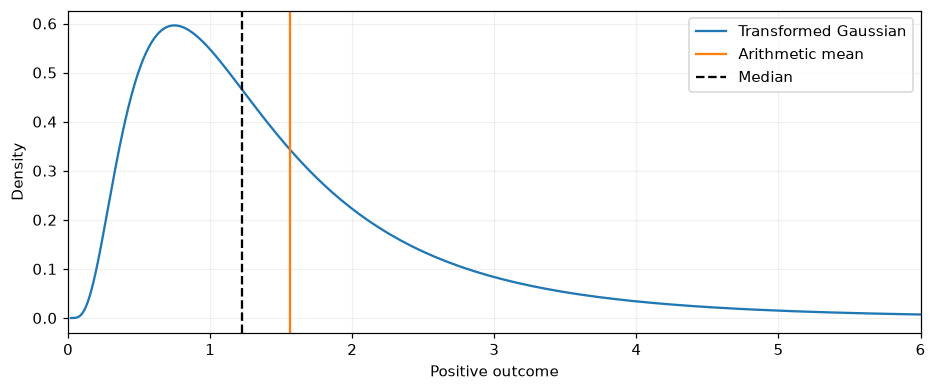

,location,observation,standard deviation,log density,location score
0,2.0,1.0,3.0,-2.073106,-0.111111


In [11]:
positive = dist.exponential(dist.normal(.2, .7))
lognormal = dist.lognormal(.2, .7)
positive_grid = np.geomspace(.02, 15, 400)
fig, ax = plt.subplots()
ax.plot(positive_grid, positive.density(positive_grid), label="Transformed Gaussian")
ax.axvline(float(lognormal.mean()), color="tab:orange", label="Arithmetic mean")
ax.axvline(float(lognormal.quantile(.5)), color="black", linestyle="--", label="Median")
ax.set(xlabel="Positive outcome", ylabel="Density", xlim=(0, 6))
ax.legend()
plt.show()

import torch
location = torch.tensor(2., dtype=torch.float64, requires_grad=True)
tensor_law = dist.tensor.normal(location, torch.tensor(3., dtype=torch.float64))
log_probability = tensor_law.log_density(torch.tensor(1., dtype=torch.float64))
score = torch.autograd.grad(log_probability, location)[0]
pd.DataFrame({"location": [2.], "observation": [1.], "standard deviation": [3.],
              "log density": [float(log_probability.detach())], "location score": [float(score)]})

A negative score means increasing the location reduces the likelihood of this observation. Try moving the observation to the other side of the location, or changing the scale: the sign and sensitivity should change for interpretable reasons.

The examples separate finite scenario probabilities, continuous densities, and derivatives of densities. The [distribution catalog](../docs/distributions.md) describes custom adapters and the operations each law supports.